In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [57]:
df = pd.read_csv("../../datasets/a_regression_car_price/cleaned_car_prices.csv")

In [58]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Price"])
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

print(X_train.shape, X_test.shape)

(4209, 12) (1804, 12)


## Numerical

### Imputation

In [59]:
from sklearn.impute import SimpleImputer

num_cols = ["Kilometers_Driven", "Mileage", "Engine", "Power", "Seats", "Car_Age"]
imputer = SimpleImputer(strategy="median")

X_train_num = imputer.fit_transform(X_train[num_cols])
X_test_num = imputer.transform(X_test[num_cols])

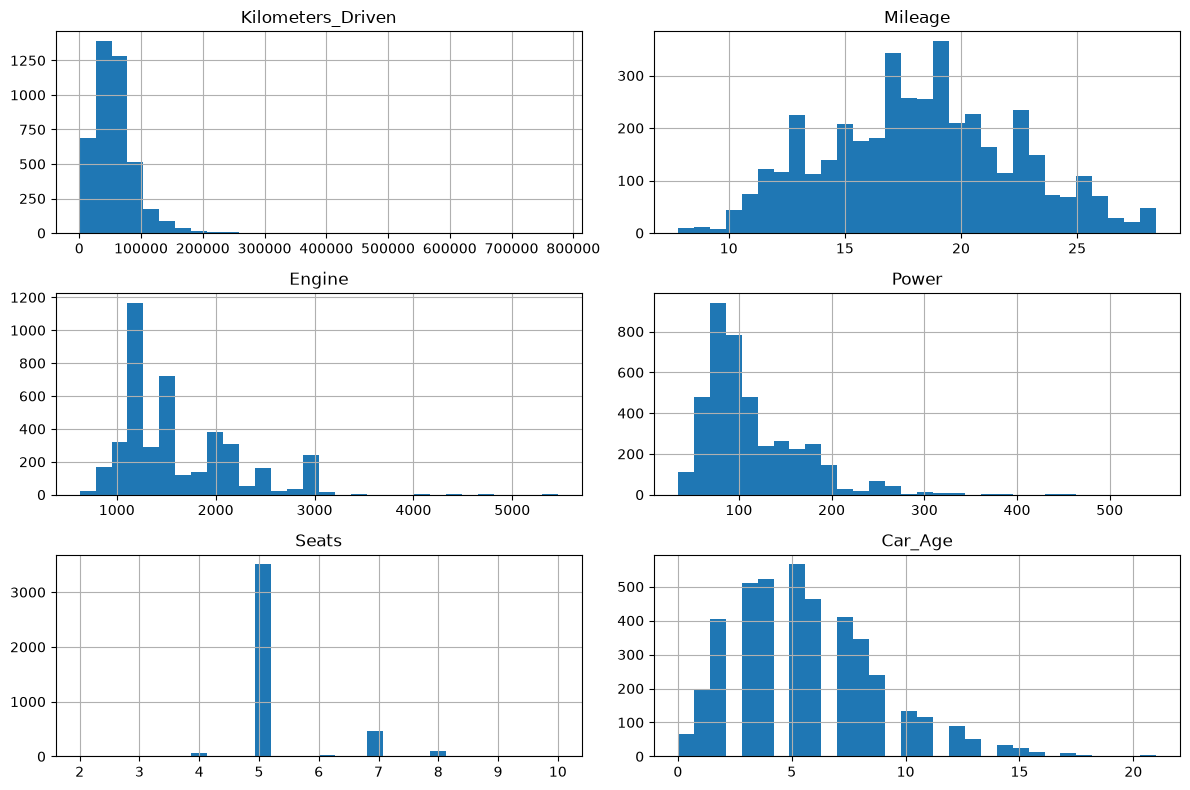

Features Skewness:
 Kilometers_Driven    4.137504
Seats                2.054041
Power                1.703120
Engine               1.266436
Car_Age              0.839284
Mileage              0.106187
dtype: float64

Target (Price) Skewness: 2.919956339155662


In [60]:
X_train.select_dtypes(include="number").hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

print("Features Skewness:\n", X_train.select_dtypes(include="number").skew().sort_values(ascending=False))
print("\nTarget (Price) Skewness:", y_train.skew())

### Outliers Detection & Scaling 

In [61]:
# Detecting Outliers by IQR in X_train_num
def detect_outliers_iqr(series, factor=1.5):
    Q1 = np.nanpercentile(series, 25)
    Q3 = np.nanpercentile(series, 75)
    IQR = Q3 - Q1
    lower = Q1 - factor * IQR
    upper = Q3 + factor * IQR
    outliers = series[(series < lower) | (series > upper)]
    return len(outliers), lower, upper

In [62]:
for col in num_cols:
    iqr_count, iqr_low, iqr_high = detect_outliers_iqr(X_train[col], factor=1.5)
    
    print(f"{col} IQR   ->  {iqr_count} outliers | Bounds: [{iqr_low:.1f} to {iqr_high:.1f}]")

Kilometers_Driven IQR   ->  149 outliers | Bounds: [-23729.0 to 130215.0]
Mileage IQR   ->  0 outliers | Bounds: [6.5 to 29.9]
Engine IQR   ->  36 outliers | Bounds: [6.0 to 3182.0]
Power IQR   ->  159 outliers | Bounds: [-16.6 to 230.9]
Seats IQR   ->  669 outliers | Bounds: [5.0 to 5.0]
Car_Age IQR   ->  33 outliers | Bounds: [-4.5 to 15.5]


In [63]:
from sklearn.preprocessing import RobustScaler

robust = RobustScaler()

X_train_robust = robust.fit_transform(X_train_num)
X_test_robust = robust.transform(X_test_num)

### Transformation

In [64]:
from sklearn.preprocessing import FunctionTransformer
log_transformer = FunctionTransformer(np.log1p, feature_names_out="one-to-one")

# num_cols: Kilometers_Driven(0), Mileage(1), Engine(2), Power(3), Seats(4), Car_Age(5)
log_indices = [0, 2, 3]
X_train_logged = X_train_num.copy()
X_test_logged = X_test_num.copy()

X_train_logged[:, log_indices] = log_transformer.fit_transform(X_train_num[:, log_indices])
X_test_logged[:, log_indices] = log_transformer.transform(X_test_num[:, log_indices])

y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

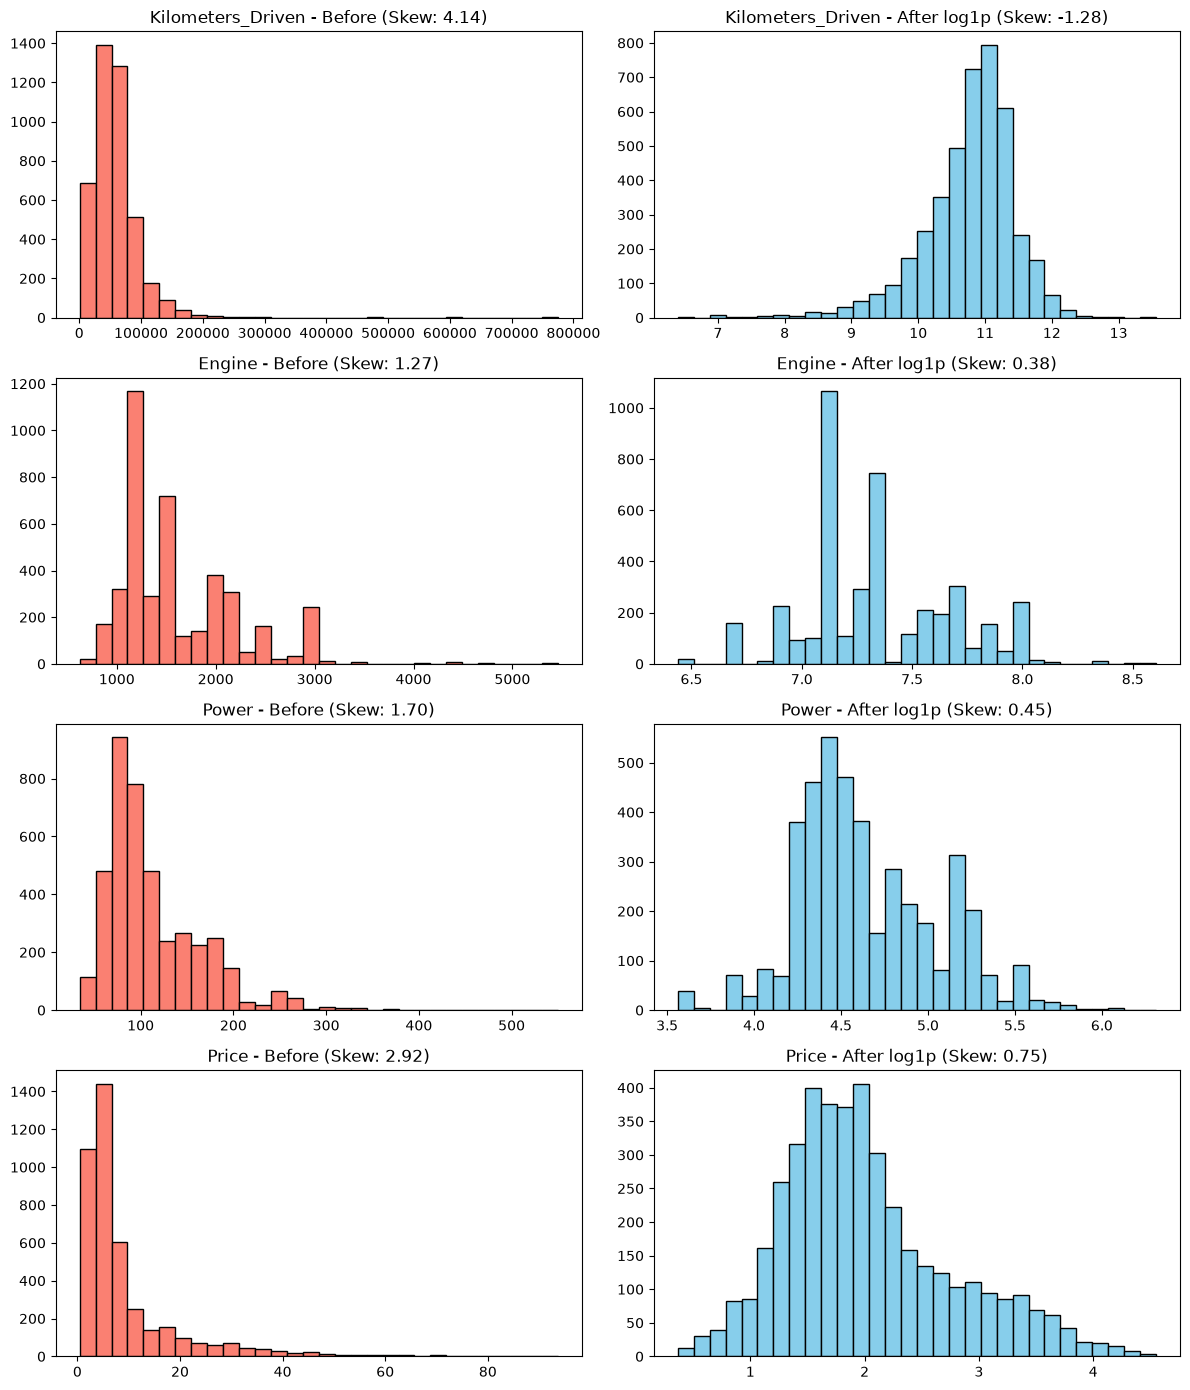

In [65]:
df_after = pd.DataFrame(X_train_logged, columns=num_cols)

cols_to_plot = ["Kilometers_Driven", "Engine", "Power", "Price"]
before_data = [X_train["Kilometers_Driven"], X_train["Engine"], X_train["Power"], y_train]
after_data  = [df_after["Kilometers_Driven"], df_after["Engine"], df_after["Power"], y_train_log]

fig, axes = plt.subplots(4, 2, figsize=(12, 14))

for i, col in enumerate(cols_to_plot):
    # Before column on the left (column 0)
    axes[i, 0].hist(before_data[i], bins=30, color="salmon", edgecolor="black")
    axes[i, 0].set_title(f"{col} - Before (Skew: {before_data[i].skew():.2f})")
    
    # After column on the right (column 1)
    axes[i, 1].hist(after_data[i], bins=30, color="skyblue", edgecolor="black")
    axes[i, 1].set_title(f"{col} - After log1p (Skew: {after_data[i].skew():.2f})")

plt.tight_layout()
plt.show()

## Categorical

### Imputation

In [66]:
from sklearn.impute import SimpleImputer

cat_cols = ['Location', 'Fuel_Type', 'Transmission', 'Owner_Type', 'Brand', 'Model']


cat_imputer = SimpleImputer(strategy="most_frequent")

X_train_cat = cat_imputer.fit_transform(X_train[cat_cols])
X_test_cat = cat_imputer.transform(X_test[cat_cols])

### Encoding

In [67]:
df_train_cat = pd.DataFrame(X_train_cat, columns=cat_cols)
df_test_cat  = pd.DataFrame(X_test_cat, columns=cat_cols)

In [68]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_cols = ["Owner_Type"]
# Fourth & Above=0, Third=1, Second=2, First=3
owner_order = ["Fourth & Above", "Third", "Second", "First"]

ord_enc = OrdinalEncoder(
    categories=[owner_order],
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

train_ord = ord_enc.fit_transform(df_train_cat[ordinal_cols])
test_ord  = ord_enc.transform(df_test_cat[ordinal_cols])

print("Ordinal shape:", train_ord.shape)

Ordinal shape: (4209, 1)


In [69]:
from sklearn.preprocessing import MinMaxScaler

ord_scaler = MinMaxScaler()

train_ord_scaled = ord_scaler.fit_transform(train_ord)
test_ord_scaled  = ord_scaler.transform(test_ord)

print("Scaled Ordinal min & max:", train_ord_scaled.min(), "to", train_ord_scaled.max())

Scaled Ordinal min & max: 0.0 to 1.0


In [70]:
from sklearn.preprocessing import OneHotEncoder

onehot_cols = ["Location", "Fuel_Type", "Transmission"]

ohe_enc = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore",
    drop="if_binary"
)

train_ohe = ohe_enc.fit_transform(df_train_cat[onehot_cols])
test_ohe  = ohe_enc.transform(df_test_cat[onehot_cols])

print("OneHot shape:", train_ohe.shape)

OneHot shape: (4209, 16)


In [71]:
%pip install category_encoders

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [72]:
from category_encoders import BinaryEncoder

binary_cols = [col for col in ["Brand", "Model"] if col in cat_cols]

bin_enc = BinaryEncoder()

train_bin = bin_enc.fit_transform(df_train_cat[binary_cols])
test_bin  = bin_enc.transform(df_test_cat[binary_cols])

print("Binary shape:", train_bin.shape)

Binary shape: (4209, 13)


## Pipeline

In [73]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, FunctionTransformer, OrdinalEncoder, OneHotEncoder, MinMaxScaler
from category_encoders import BinaryEncoder

num_log_cols   = ["Kilometers_Driven", "Engine", "Power"]
num_other_cols = ["Mileage", "Seats", "Car_Age"]
ordinal_cols   = ["Owner_Type"]
onehot_cols    = ["Location", "Fuel_Type", "Transmission"]
binary_cols    = [col for col in ["Brand", "Model"] if col in X_train.columns]


num_log_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log",     FunctionTransformer(np.log1p)),
    ("scaler",  RobustScaler())
])

num_other_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  RobustScaler())
])

owner_order = ["Fourth & Above", "Third", "Second", "First"]
ordinal_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(categories=[owner_order], handle_unknown="use_encoded_value", unknown_value=-1)),
    ("scaler",  MinMaxScaler())
])

onehot_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(sparse_output=False, handle_unknown="ignore", drop="if_binary"))
])

binary_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", BinaryEncoder())
])

preprocessor = ColumnTransformer([
    ("num_log",   num_log_pipe,   num_log_cols),
    ("num_other", num_other_pipe, num_other_cols),
    ("ordinal",   ordinal_pipe,   ordinal_cols),
    ("onehot",    onehot_pipe,    onehot_cols),
    ("binary",    binary_pipe,    binary_cols)
])

## Linear Regression (scikit-learn)

In [74]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [75]:
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

In [76]:
lr_pipeline.fit(X_train, y_train_log)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Location','Kilometers_Driven','Fuel_Type',...,'Brand','Model','Car_Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_log', ...), ('num_other', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This

In [77]:
y_train_actual = np.expm1(y_train_log)
y_test_actual = np.expm1(y_test_log)

In [78]:
y_train_pred_log_lr = lr_pipeline.predict(X_train)
y_test_pred_log_lr = lr_pipeline.predict(X_test)

y_train_pred_lr = np.expm1(y_train_pred_log_lr)
y_test_pred_lr = np.expm1(y_test_pred_log_lr)

In [79]:
def evaluate_model(y_true, y_pred, dataset_name):

    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    print(f"{dataset_name} Results")
    print("-" * 30)
    print(f"MAE  : {mae:.2f}")
    print(f"MSE  : {mse:.2f}")
    print(f"RMSE : {rmse:.2f}")
    print(f"R2   : {r2:.4f}")

In [80]:
evaluate_model(y_train_actual, y_train_pred_lr, "Training Set")
evaluate_model(y_test_actual, y_test_pred_lr, "Testing Set")

Training Set Results
------------------------------
MAE  : 2.14
MSE  : 21.53
RMSE : 4.64
R2   : 0.8131
Testing Set Results
------------------------------
MAE  : 2.20
MSE  : 21.39
RMSE : 4.62
R2   : 0.8325


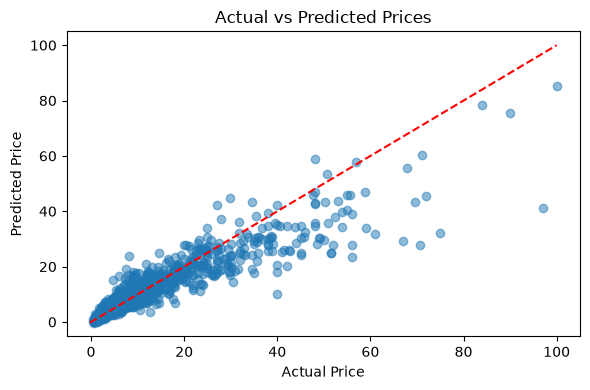

In [81]:
plt.figure(figsize=(6, 4))

plt.scatter(y_test_actual, y_test_pred_lr, alpha=0.5)

min_val = min(y_test_actual.min(), y_test_pred_lr.min())
max_val = max(y_test_actual.max(), y_test_pred_lr.max())

plt.plot([min_val, max_val], [min_val, max_val], "r--")

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Prices")

plt.tight_layout()
plt.show()

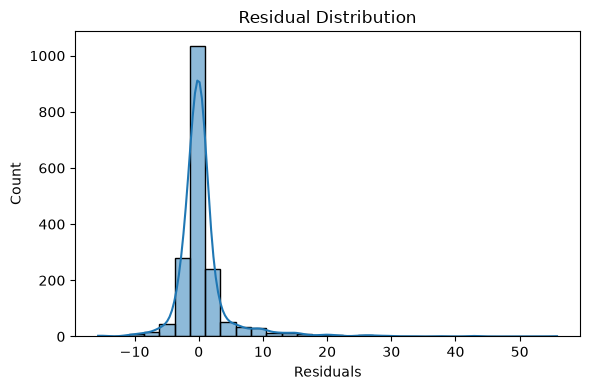

In [82]:
residuals = y_test_actual - y_test_pred_lr
plt.figure(figsize=(6, 4))

sns.histplot(residuals, bins=30, kde=True)

plt.xlabel("Residuals")
plt.title("Residual Distribution")

plt.tight_layout()
plt.show()

## Linear Regression (From Scratch) gd

In [83]:
import numpy as np
from numpy.linalg import norm
import matplotlib.pyplot as plt


In [84]:
def add_bias(X):
    X = np.asarray(X, dtype=np.float64)
    return np.c_[np.ones((X.shape[0], 1)), X]


In [85]:
def cost_f(X, t, weights):
    examples = X.shape[0]
    error = np.dot(X, weights) - t
    return np.sum(error ** 2) / (2 * examples)

In [86]:
def f_derivative(X, t, weights):
    examples = X.shape[0]
    error = np.dot(X, weights) - t
    return np.dot(X.T, error) / examples

In [87]:
def gradient_descent_linear_regression(X, t, learning_rate=0.01, precision=0.00001, max_iter=10000):
    examples, features = X.shape
    np.random.seed(42)
    cur_weights = np.random.rand(features)        
    last_weights = np.full(features, float('inf'))
    cost_history = []

    print(f'Initial Random Cost: {cost_f(X, t, cur_weights):.4f}')

    iter_count = 0
    while norm(cur_weights - last_weights) > precision and iter_count < max_iter:
        last_weights = cur_weights.copy()

        gradient = f_derivative(X, t, cur_weights)
        cur_weights -= gradient * learning_rate

        cost_history.append(cost_f(X, t, cur_weights))
        iter_count += 1

    print(f'Total Iterations: {iter_count}')
    print(f'Optimal Cost: {cost_f(X, t, cur_weights):.4f}')
    return cur_weights, cost_history

In [88]:
X_train_final = preprocessor.fit_transform(X_train)
X_test_final  = preprocessor.transform(X_test)

In [89]:
X_train_b = add_bias(X_train_final)
X_test_b  = add_bias(X_test_final)
t_train   = np.asarray(y_train_log, dtype=np.float64).reshape(-1)

In [90]:
gd_weights, cost_history = gradient_descent_linear_regression(
    X_train_b, t_train,
    learning_rate=0.05,  
    precision=1e-5,
    max_iter=10000
)

Initial Random Cost: 5.8279
Total Iterations: 10000
Optimal Cost: 0.0303


In [91]:
y_train_pred_log_gd = np.dot(X_train_b, gd_weights)
y_test_pred_log_gd  = np.dot(X_test_b, gd_weights)
y_train_pred_gd = np.expm1(y_train_pred_log_gd)
y_test_pred_gd  = np.expm1(y_test_pred_log_gd)

In [92]:
evaluate_model(y_train_actual, y_train_pred_gd, "Gradient Descent - Training Set")
print()
evaluate_model(y_test_actual, y_test_pred_gd, "Gradient Descent - Testing Set")

Gradient Descent - Training Set Results
------------------------------
MAE  : 2.14
MSE  : 21.55
RMSE : 4.64
R2   : 0.8129

Gradient Descent - Testing Set Results
------------------------------
MAE  : 2.20
MSE  : 21.41
RMSE : 4.63
R2   : 0.8324


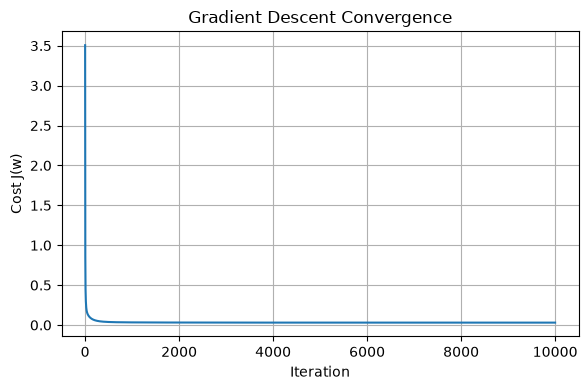

In [93]:
plt.figure(figsize=(6, 4))
plt.plot(cost_history)
plt.xlabel("Iteration")
plt.ylabel("Cost J(w)")
plt.title("Gradient Descent Convergence")
plt.grid()
plt.tight_layout()
plt.show()

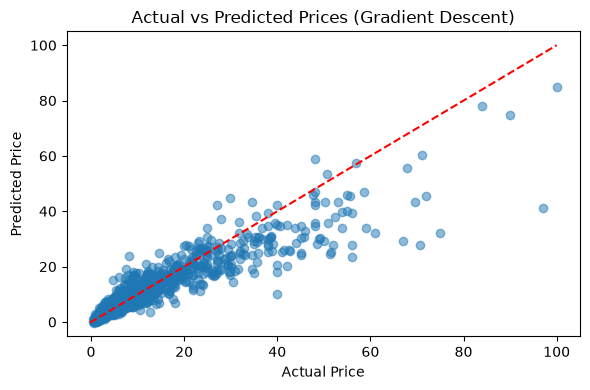

In [94]:
plt.figure(figsize=(6, 4))
plt.scatter(y_test_actual, y_test_pred_gd, alpha=0.5)
min_val = min(y_test_actual.min(), y_test_pred_gd.min())
max_val = max(y_test_actual.max(), y_test_pred_gd.max())
plt.plot([min_val, max_val], [min_val, max_val], "r--")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Prices (Gradient Descent)")
plt.tight_layout()
plt.show()